# NN_L11_shap_beeswarm

**Beeswarm of Kernel SHAP values of an MLP credit model on HMEQ: each dot is one applicant, colour = rank of the feature value.**

Neural Networks and Deep Learning (NN), Lecture 11 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L11/NN_L11_shap_beeswarm/NN_L11_shap_beeswarm.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

In [3]:
import torch, torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from scipy import stats
import shap
SEED = 20261108; np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(4)
class MLP(nn.Module):
    def __init__(self, d, h1=64, h2=32, p=0.1):
        super().__init__()
        self.f = nn.Sequential(nn.Linear(d, h1), nn.ReLU(), nn.Dropout(p), nn.Linear(h1, h2), nn.ReLU(), nn.Dropout(p), nn.Linear(h2, 1))
    def forward(self, x): return self.f(x).squeeze(-1)
def train_mlp(seed, Xa, ya, Xv, yv, w_pos=1.0, epochs=300, patience=25, task='clf', lr=1e-3, sw_valid=None):
    torch.manual_seed(seed); rng = np.random.default_rng(seed); net = MLP(Xa.shape[1])
    opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=1e-4)
    Xt, yt = torch.from_numpy(Xa), torch.from_numpy(ya.astype(np.float32)); best, state, bad = -np.inf, None, 0
    for ep in range(epochs):
        net.train(); perm = rng.permutation(len(Xa))
        for j in range(0, len(Xa), 256):
            b = torch.from_numpy(perm[j:j + 256]); out = net(Xt[b])
            if task == 'clf':
                w = torch.where(yt[b] > 0, torch.tensor(w_pos), torch.tensor(1.0))
                loss = nn.functional.binary_cross_entropy_with_logits(out, yt[b], weight=w)
            else:
                loss = ((out - yt[b]) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        net.eval()
        with torch.no_grad(): pv = net(torch.from_numpy(Xv)).numpy()
        sc = (roc_auc_score(yv, pv) if w_pos == 1.0 else average_precision_score(yv, pv, sample_weight=sw_valid)) if task == 'clf' else -np.mean((pv - yv) ** 2)
        if sc > best: best, state, bad = sc, {k: v.clone() for k, v in net.state_dict().items()}, 0
        else:
            bad += 1
            if bad > patience: break
    net.load_state_dict(state); net.eval(); return net
def logit_fn(net):
    def f(X):
        with torch.no_grad(): return net(torch.from_numpy(np.asarray(X, dtype=np.float32))).numpy().astype(np.float64)
    return f
sig = lambda z: 1 / (1 + np.exp(-z))

In [4]:
h = pd.read_csv(DATA + 'hmeq.csv')
NUM = ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC']
y_all = h['BAD'].values; idx = np.arange(len(h))
i_tr, i_te = train_test_split(idx, test_size=0.2, stratify=y_all, random_state=SEED)
i_tr, i_va = train_test_split(i_tr, test_size=0.25, stratify=y_all[i_tr], random_state=SEED)
med = h.iloc[i_tr][NUM].median()
XR = pd.DataFrame({c: h[c].fillna(med[c]) for c in NUM})
XR['DEBTINC_missing'] = h['DEBTINC'].isna().astype(float); XR['REASON_HomeImp'] = (h['REASON'] == 'HomeImp').astype(float)
for j in ['Mgr', 'Office', 'Other', 'ProfExe', 'Sales', 'Self']: XR['JOB_' + j] = (h['JOB'] == j).astype(float)
FEATS = list(XR.columns); mu, sdv = XR.iloc[i_tr].mean(), XR.iloc[i_tr].std()
XS = ((XR - mu) / sdv).values.astype(np.float32)
Xtr, Xva, Xte = XS[i_tr], XS[i_va], XS[i_te]; ytr, yva, yte = y_all[i_tr], y_all[i_va], y_all[i_te]
rng = np.random.default_rng(SEED); BG = Xtr[rng.choice(len(Xtr), 100, replace=False)]; i_sub = rng.choice(len(Xte), 400, replace=False); Xsub = Xte[i_sub]
lrm = LogisticRegression(C=1.0, max_iter=2000).fit(Xtr, ytr)
show('hmeq.n', 'loans', int(len(h))); show('hmeq.n_test', 'test loans', int(len(i_te)))
show('perf.lr_auc', 'logistic regression test AUC', round(float(roc_auc_score(yte, lrm.predict_proba(Xte)[:, 1])), 3))
net0 = train_mlp(SEED, Xtr, ytr, Xva, yva); f0 = logit_fn(net0)
print('MLP test AUC (seed 20261108):', round(roc_auc_score(yte, f0(Xte)), 3))

loans = 5960   [hmeq.n]
test loans = 1192   [hmeq.n_test]
logistic regression test AUC = 0.909   [perf.lr_auc]


MLP test AUC (seed 20261108): 0.937


In [5]:
np.random.seed(SEED); ex = shap.KernelExplainer(f0, BG)
NE = 150
sv = np.array(ex.shap_values(Xsub[:NE], nsamples=400, silent=True)); base = float(f0(BG).mean())
print('additivity error:', float(np.abs(sv.sum(1) + base - f0(Xsub[:NE])).max()))

additivity error: 1.9073486328125e-06


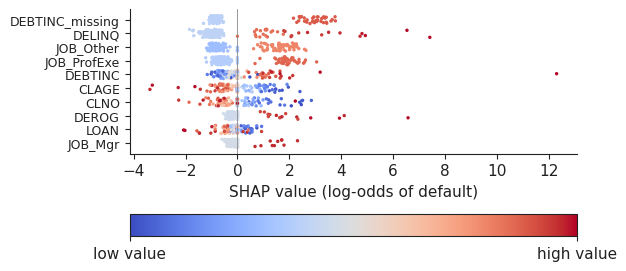

In [6]:
top = np.argsort(-np.abs(sv).mean(0))[:10][::-1]
fig, ax = plt.subplots(figsize=(6.4, 2.9))
for row, j in enumerate(top):
    q = stats.rankdata(Xsub[:NE, j]) / NE
    sc = ax.scatter(sv[:, j], row + (np.random.default_rng(j).random(NE) - 0.5) * 0.6, c=q, cmap='coolwarm', s=6, lw=0, vmin=0, vmax=1)
ax.axvline(0, color='#8a8a8a', lw=0.6); ax.set_yticks(range(10)); ax.set_yticklabels([FEATS[j] for j in top], fontsize=9)
ax.set_xlabel('SHAP value (log-odds of default)'); cb = fig.colorbar(sc, orientation='horizontal', pad=0.25, ticks=[0, 1]); cb.ax.set_xticklabels(['low value', 'high value'])
fig.tight_layout()
fig.savefig('shap_beeswarm.png', dpi=200, transparent=True, bbox_inches='tight'); plt.show()